In [1]:

import pandas as pd
import numpy as np

# VISIONGUARD HITO 2
# Datos 100% SIMULADOS para fines académicos.
# No representan mediciones reales de una fábrica.

rng = np.random.default_rng(20261112)
fechas = pd.date_range("2026-05-01", periods=180)
tasas_base = {"L1": 0.045, "L2": 0.060, "L3": 0.075}
registros = []

for dia, fecha in enumerate(fechas):
    for linea, base in tasas_base.items():
        total = int(rng.integers(180, 321))
        semanal = 0.008 * np.sin(2 * np.pi * dia / 7)
        cambio = 0.018 if linea == "L2" and dia >= 120 else 0
        ruido = rng.uniform(-0.012, 0.012)

        tasa = np.clip(base + semanal + cambio + ruido, 0.01, 0.20)
        defectuosas = int(rng.binomial(total, tasa))

        registros.append({
            "fecha": fecha,
            "linea": linea,
            "piezas_inspeccionadas": total,
            "piezas_defectuosas": defectuosas,
            "tasa_defectos": defectuosas / total,
            "origen": "SIMULADO_ACADEMICO_NO_REAL"
        })

df = pd.DataFrame(registros)
df.to_csv("tasa_defectos_diaria_SIMULADA.csv", index=False)

print("Registros:", len(df))
print("Días:", df["fecha"].nunique())
print("Líneas:", df["linea"].nunique())
display(df.head())


Registros: 540
Días: 180
Líneas: 3


,fecha,linea,piezas_inspeccionadas,piezas_defectuosas,tasa_defectos,origen
0,2026-05-01,L1,318,10,0.031447,SIMULADO_ACADEMICO_NO_REAL
1,2026-05-01,L2,303,16,0.052805,SIMULADO_ACADEMICO_NO_REAL
2,2026-05-01,L3,192,15,0.078125,SIMULADO_ACADEMICO_NO_REAL
3,2026-05-02,L1,226,8,0.035398,SIMULADO_ACADEMICO_NO_REAL
4,2026-05-02,L2,292,12,0.041096,SIMULADO_ACADEMICO_NO_REAL


VISIONGUARD - VALIDACIÓN DE DATOS
Valores faltantes: 0
Registros duplicados: 0

Tasa promedio de defectos por línea:
linea
L1    4.56
L2    6.59
L3    7.57
Name: tasa_defectos, dtype: float64


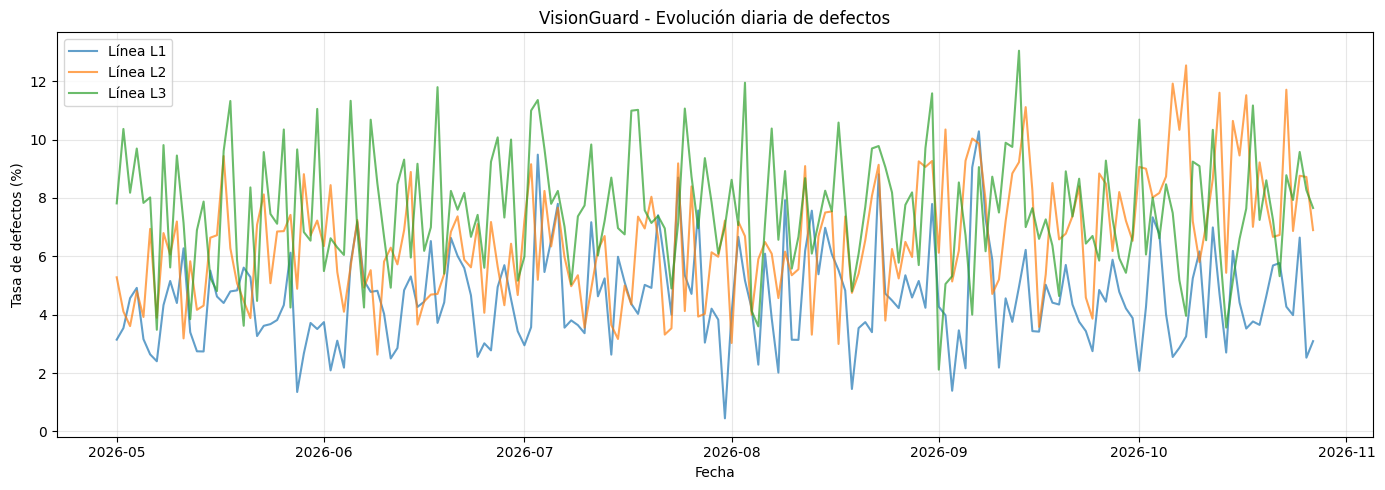

In [2]:

import matplotlib.pyplot as plt

# 1. Validación de los datos
print("VISIONGUARD - VALIDACIÓN DE DATOS")
print("Valores faltantes:", df.isnull().sum().sum())
print("Registros duplicados:", df.duplicated(["fecha", "linea"]).sum())

assert (df["piezas_defectuosas"] <= df["piezas_inspeccionadas"]).all()
assert df["tasa_defectos"].between(0, 1).all()

print("\nTasa promedio de defectos por línea:")
print((df.groupby("linea")["tasa_defectos"].mean() * 100).round(2))

# 2. Visualización de series temporales
plt.figure(figsize=(14, 5))

for linea in sorted(df["linea"].unique()):
    datos = df[df["linea"] == linea].sort_values("fecha")
    plt.plot(
        datos["fecha"],
        datos["tasa_defectos"] * 100,
        label=f"Línea {linea}",
        alpha=0.7
    )

plt.title("VisionGuard - Evolución diaria de defectos")
plt.xlabel("Fecha")
plt.ylabel("Tasa de defectos (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [4]:

# PASO 8 - División cronológica sin fuga de datos

df = df.sort_values(["fecha", "linea"]).reset_index(drop=True)

fechas = sorted(df["fecha"].unique())
n = len(fechas)

corte_train = round(n * 0.70)
corte_val = round(n * 0.85)

fechas_train = fechas[:corte_train]
fechas_val = fechas[corte_train:corte_val]
fechas_test = fechas[corte_val:]

train = df[df["fecha"].isin(fechas_train)].copy()
val = df[df["fecha"].isin(fechas_val)].copy()
test = df[df["fecha"].isin(fechas_test)].copy()

# Verificar separación temporal
assert train["fecha"].max() < val["fecha"].min()
assert val["fecha"].max() < test["fecha"].min()

print("VISIONGUARD - DIVISIÓN TEMPORAL")
print("Entrenamiento:", len(train), "registros")
print("Validación:", len(val), "registros")
print("Prueba:", len(test), "registros")

print("\nDistribución por línea:")
print("Train:", train.groupby("linea").size().to_dict())
print("Val:", val.groupby("linea").size().to_dict())
print("Test:", test.groupby("linea").size().to_dict())

print("\nSeparación temporal correcta.")


VISIONGUARD - DIVISIÓN TEMPORAL
Entrenamiento: 378 registros
Validación: 81 registros
Prueba: 81 registros

Distribución por línea:
Train: {'L1': 126, 'L2': 126, 'L3': 126}
Val: {'L1': 27, 'L2': 27, 'L3': 27}
Test: {'L1': 27, 'L2': 27, 'L3': 27}

Separación temporal correcta.


In [5]:

import numpy as np
import pandas as pd

# VISIONGUARD - HITO 2
# PASO 9: MODELO BASE - PROMEDIO MOVIL DE 7 DIAS
# Datos simulados para fines academicos

serie = df.sort_values(
    ["linea", "fecha"]
).copy()

# Pronostico de un dia hacia adelante.
# shift(1) evita usar la tasa del dia a predecir.
serie["prediccion_base"] = (
    serie.groupby("linea")["tasa_defectos"]
    .transform(
        lambda s: s.shift(1).rolling(
            window=7, min_periods=7
        ).mean()
    )
)

# Evaluar sobre fechas de validacion y prueba
validacion_base = serie[
    serie["fecha"].isin(fechas_val)
].dropna(subset=["prediccion_base"])

prueba_base = serie[
    serie["fecha"].isin(fechas_test)
].dropna(subset=["prediccion_base"])

def evaluar_modelo(datos):
    real = datos["tasa_defectos"].to_numpy()
    pred = datos["prediccion_base"].to_numpy()

    mae = np.mean(np.abs(real - pred)) * 100
    rmse = np.sqrt(np.mean((real - pred)**2)) * 100

    return round(mae, 4), round(rmse, 4)

mae_val, rmse_val = evaluar_modelo(validacion_base)
mae_test, rmse_test = evaluar_modelo(prueba_base)

print("VISIONGUARD - MODELO BASE")
print("Modelo: promedio movil de 7 dias")
print("Horizonte: 1 dia adelante")
print("\nVALIDACION")
print("MAE:", mae_val, "puntos porcentuales")
print("RMSE:", rmse_val, "puntos porcentuales")

print("\nPRUEBA")
print("MAE:", mae_test, "puntos porcentuales")
print("RMSE:", rmse_test, "puntos porcentuales")

print("\nEjemplos de prediccion:")
display(
    prueba_base[[
        "fecha", "linea",
        "tasa_defectos", "prediccion_base"
    ]].head(10)
)


VISIONGUARD - MODELO BASE
Modelo: promedio movil de 7 dias
Horizonte: 1 dia adelante

VALIDACION
MAE: 1.5707 puntos porcentuales
RMSE: 1.9919 puntos porcentuales

PRUEBA
MAE: 1.6167 puntos porcentuales
RMSE: 1.9631 puntos porcentuales

Ejemplos de prediccion:


,fecha,linea,tasa_defectos,prediccion_base
459,2026-10-01,L1,0.020761,0.044003
462,2026-10-02,L1,0.042654,0.043042
465,2026-10-03,L1,0.073359,0.042213
468,2026-10-04,L1,0.067633,0.046344
471,2026-10-05,L1,0.040146,0.047602
474,2026-10-06,L1,0.025510,0.046505
477,2026-10-07,L1,0.028662,0.044128
480,2026-10-08,L1,0.032558,0.042675
483,2026-10-09,L1,0.052434,0.044360
486,2026-10-10,L1,0.061674,0.045758


In [6]:

# VISIONGUARD - HITO 2
# PASO 10: PREPARACION DE DATOS PARA GRU

import numpy as np
import pandas as pd

np.random.seed(42)

VENTANA = 7
lineas = sorted(df["linea"].unique())

# Normalizacion calculada SOLO con entrenamiento
media_train = train["tasa_defectos"].mean()
std_train = train["tasa_defectos"].std(ddof=0)

assert std_train > 0

# Fechas que definen cada conjunto
dias_train = set(pd.to_datetime(fechas_train))
dias_val = set(pd.to_datetime(fechas_val))
dias_test = set(pd.to_datetime(fechas_test))

conjuntos = {
    "train": {"X": [], "y": []},
    "val": {"X": [], "y": []},
    "test": {"X": [], "y": []}
}

for indice_linea, linea in enumerate(lineas):

    datos = (
        df[df["linea"] == linea]
        .sort_values("fecha")
        .reset_index(drop=True)
    )

    tasas = datos["tasa_defectos"].to_numpy()

    for i in range(VENTANA, len(datos)):

        # Solo los siete dias ANTERIORES
        historial = tasas[i-VENTANA:i]

        # Primera variable: tasa normalizada
        # Tres variables adicionales: identificacion de linea
        entrada = np.zeros((VENTANA, 4), dtype=np.float32)

        entrada[:, 0] = (
            historial - media_train
        ) / std_train

        entrada[:, indice_linea + 1] = 1.0

        objetivo = (
            tasas[i] - media_train
        ) / std_train

        fecha_objetivo = pd.Timestamp(
            datos.loc[i, "fecha"]
        )

        if fecha_objetivo in dias_train:
            nombre = "train"
        elif fecha_objetivo in dias_val:
            nombre = "val"
        elif fecha_objetivo in dias_test:
            nombre = "test"
        else:
            raise ValueError("Fecha fuera de los conjuntos")

        conjuntos[nombre]["X"].append(entrada)
        conjuntos[nombre]["y"].append(objetivo)

# Convertir a arrays para TensorFlow/Keras
for nombre, contenido in conjuntos.items():
    contenido["X"] = np.array(
        contenido["X"], dtype=np.float32
    )
    contenido["y"] = np.array(
        contenido["y"], dtype=np.float32
    )

X_train = conjuntos["train"]["X"]
y_train = conjuntos["train"]["y"]

X_val = conjuntos["val"]["X"]
y_val = conjuntos["val"]["y"]

X_test = conjuntos["test"]["X"]
y_test = conjuntos["test"]["y"]

print("VISIONGUARD - SECUENCIAS GRU")
print("Entrenamiento:", X_train.shape)
print("Validacion:", X_val.shape)
print("Prueba:", X_test.shape)

print("\nVariables por dia:", X_train.shape[2])
print("Dias de historial:", X_train.shape[1])
print("Sin fuga de datos futuros.")

assert X_train.shape == (357, 7, 4)
assert X_val.shape == (81, 7, 4)
assert X_test.shape == (81, 7, 4)


VISIONGUARD - SECUENCIAS GRU
Entrenamiento: (357, 7, 4)
Validacion: (81, 7, 4)
Prueba: (81, 7, 4)

Variables por dia: 4
Dias de historial: 7
Sin fuga de datos futuros.


Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 0.8220 - mae: 0.7166 - val_loss: 0.8244 - val_mae: 0.6949 - learning_rate: 0.0020
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.6930 - mae: 0.6488 - val_loss: 0.8155 - val_mae: 0.7049 - learning_rate: 0.0020
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.6862 - mae: 0.6569 - val_loss: 0.8529 - val_mae: 0.7235 - learning_rate: 0.0020
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.6788 - mae: 0.6568 - val_loss: 0.8709 - val_mae: 0.7263 - learning_rate: 0.0020
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.6729 - mae: 0.6517 - val_loss: 0.8746 - val_mae: 0.7238 - learning_rate: 0.0020
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.6694 - mae: 0.6490 - val_loss: 0.8835 - val_mae: 0.7258 - learning_rate: 0.0020
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.6670 - mae: 0.6484 - val_loss: 0.8918 - val_mae: 0.7288 - learning_rate: 0.0020
Epoch 

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 24)             │         2,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 12)             │           300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            13 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,421 (28.99 KB)

 Trainable params: 2,473 (9.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 4,948 (19.33 KB)

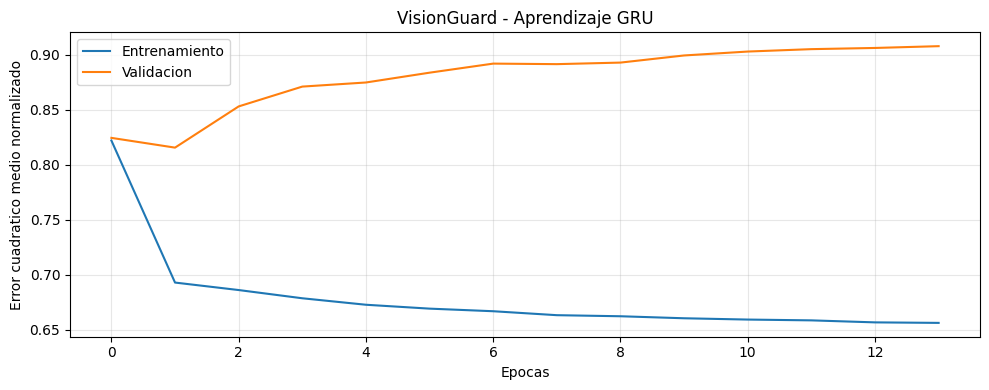

In [7]:

# VISIONGUARD INDUSTRIAL - HITO 2
# PASO 11: ENTRENAMIENTO MODELO GRU
# Datos simulados con fines academicos

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Reproducibilidad
tf.keras.utils.set_random_seed(42)

# Arquitectura del modelo
modelo_gru = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(7, 4)),

    tf.keras.layers.GRU(
        units=24,
        activation="tanh"
    ),

    tf.keras.layers.Dense(
        units=12,
        activation="relu"
    ),

    tf.keras.layers.Dense(
        units=1
    )
])

# Configuracion
modelo_gru.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.002
    ),
    loss="mse",
    metrics=["mae"]
)

# Evitar sobreajuste
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True
)

reducir_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=0.00001
)

# Entrenamiento
historial_gru = modelo_gru.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop, reducir_lr],
    verbose=1
)

print("\nVISIONGUARD - GRU ENTRENADA")
print("Epocas ejecutadas:", len(historial_gru.history["loss"]))
print("Mejor perdida de validacion:",
      round(min(historial_gru.history["val_loss"]), 5))

modelo_gru.summary()

# Curva de aprendizaje
plt.figure(figsize=(10, 4))
plt.plot(historial_gru.history["loss"],
         label="Entrenamiento")
plt.plot(historial_gru.history["val_loss"],
         label="Validacion")

plt.title("VisionGuard - Aprendizaje GRU")
plt.xlabel("Epocas")
plt.ylabel("Error cuadratico medio normalizado")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [8]:

# VISIONGUARD HITO 2 - PASO 12
# Evaluacion final GRU vs promedio movil
# Datos simulados, horizonte de 1 dia

import numpy as np
import pandas as pd

# Predicciones de la GRU
pred_normalizadas = modelo_gru.predict(
    X_test, verbose=0
).flatten()

# Recuperar tasas originales
pred_gru = (
    pred_normalizadas * std_train + media_train
)

real_gru = y_test * std_train + media_train

# Predicciones del promedio movil
base = prueba_base.sort_values(
    ["linea", "fecha"]
).reset_index(drop=True)

real = base["tasa_defectos"].to_numpy()
pred_base = base["prediccion_base"].to_numpy()

# Verificar comparacion sobre los mismos datos
assert len(real) == len(real_gru) == 81
assert np.allclose(real, real_gru, atol=1e-6)

def metricas(real, pred):
    mae = np.mean(np.abs(real - pred)) * 100
    rmse = np.sqrt(np.mean((real - pred)**2)) * 100
    return round(mae, 4), round(rmse, 4)

mae_base, rmse_base = metricas(real, pred_base)
mae_gru, rmse_gru = metricas(real, pred_gru)

resultados = pd.DataFrame({
    "Modelo": ["Promedio movil 7 dias", "GRU"],
    "MAE (pp)": [mae_base, mae_gru],
    "RMSE (pp)": [rmse_base, rmse_gru]
})

print("VISIONGUARD - COMPARACION FINAL")
display(resultados)

ganador = (
    "GRU" if mae_gru < mae_base
    else "Promedio movil"
    if mae_base < mae_gru
    else "Empate"
)

print("Mejor modelo segun MAE:", ganador)

print("\nMejora relativa GRU en MAE (%):")
print(round(
    (mae_base - mae_gru) / mae_base * 100, 2
))

print("\nPredicciones GRU fuera de [0, 1]:",
      int(((pred_gru < 0) | (pred_gru > 1)).sum()))


VISIONGUARD - COMPARACION FINAL


,Modelo,MAE (pp),RMSE (pp)
0,Promedio movil 7 dias,1.6167,1.9631
1,GRU,1.7668,2.2624


Mejor modelo segun MAE: Promedio movil

Mejora relativa GRU en MAE (%):
-9.28

Predicciones GRU fuera de [0, 1]: 0


In [9]:

# VISIONGUARD - PASO 13
# Comparacion en VALIDACION

pred_val_gru = (
    modelo_gru.predict(X_val, verbose=0).flatten()
    * std_train + media_train
)

real_val_gru = y_val * std_train + media_train

base_val = validacion_base.sort_values(
    ["linea", "fecha"]
).reset_index(drop=True)

real_val_base = base_val["tasa_defectos"].to_numpy()
pred_val_base = base_val["prediccion_base"].to_numpy()

assert np.allclose(
    real_val_base, real_val_gru, atol=1e-6
)

mae_b, rmse_b = metricas(real_val_base, pred_val_base)
mae_g, rmse_g = metricas(real_val_gru, pred_val_gru)

comparacion = pd.DataFrame({
    "Modelo": ["Promedio movil", "GRU"],
    "MAE (pp)": [mae_b, mae_g],
    "RMSE (pp)": [rmse_b, rmse_g]
})

display(comparacion)

seleccionado = (
    "Promedio movil" if mae_b <= mae_g else "GRU"
)

print("Modelo seleccionado por validacion:", seleccionado)
print("Evaluacion realizada con datos simulados.")


,Modelo,MAE (pp),RMSE (pp)
0,Promedio movil,1.5707,1.9919
1,GRU,1.5468,1.9817


Modelo seleccionado por validacion: GRU
Evaluacion realizada con datos simulados.


In [10]:

# VISIONGUARD HITO 2 - PASO 14
# Guardar modelo y resultados en Google Drive

from google.colab import drive
from pathlib import Path
import json

drive.mount("/content/drive")

carpeta = Path(
    "/content/drive/MyDrive/VisionGuard_Industrial/"
    "Hito2/Series_Temporales"
)

carpeta.mkdir(parents=True, exist_ok=True)

# 1. Guardar modelo GRU entrenado
modelo_gru.save(
    str(carpeta / "visionguard_gru.keras")
)

# 2. Guardar configuracion y metricas
resultados_finales = {
    "proyecto": "VisionGuard Industrial Hito 2",
    "origen_datos": "SIMULADOS_ACADEMICOS",
    "variable": "tasa_diaria_defectos",
    "horizonte_dias": 1,
    "ventana_dias": 7,
    "lineas": list(lineas),
    "media_train": float(media_train),
    "std_train": float(std_train),
    "seleccion_por_validacion": seleccionado,
    "validacion": {
        "promedio_movil_mae_pp": float(mae_b),
        "gru_mae_pp": float(mae_g)
    },
    "prueba": {
        "promedio_movil_mae_pp": float(mae_base),
        "gru_mae_pp": float(mae_gru),
        "promedio_movil_rmse_pp": float(rmse_base),
        "gru_rmse_pp": float(rmse_gru)
    },
    "observacion": (
        "GRU obtuvo menor MAE en validacion, "
        "pero el promedio movil fue mejor en prueba."
    )
}

with open(
    carpeta / "metricas_series_temporales.json",
    "w",
    encoding="utf-8"
) as archivo:
    json.dump(
        resultados_finales,
        archivo,
        indent=2,
        ensure_ascii=False
    )

print("VISIONGUARD - ARCHIVOS GUARDADOS")
print("Modelo GRU: OK")
print("Metricas y configuracion: OK")
print("Ubicacion:", carpeta)


Mounted at /content/drive
VISIONGUARD - ARCHIVOS GUARDADOS
Modelo GRU: OK
Metricas y configuracion: OK
Ubicacion: /content/drive/MyDrive/VisionGuard_Industrial/Hito2/Series_Temporales


In [11]:

# VISIONGUARD HITO 2 - PASO 16
# Guardar datos simulados en Google Drive

archivo_csv = carpeta / "tasa_defectos_diaria_SIMULADA.csv"

df.sort_values(["fecha", "linea"]).to_csv(
    archivo_csv,
    index=False
)

print("VISIONGUARD - DATOS GUARDADOS")
print("Archivo:", archivo_csv.name)
print("Registros:", len(df))
print("Origen: SIMULADO ACADEMICO")
print("Estado: OK")


VISIONGUARD - DATOS GUARDADOS
Archivo: tasa_defectos_diaria_SIMULADA.csv
Registros: 540
Origen: SIMULADO ACADEMICO
Estado: OK


In [12]:

# VISIONGUARD HITO 2 - PASO 17
# Pronosticos de las tres lineas de produccion
# Datos SIMULADOS para demostracion academica

import numpy as np
import pandas as pd
import json

entradas = []
historiales = []

lineas_ordenadas = sorted(df["linea"].unique())

for indice, linea in enumerate(lineas_ordenadas):
    datos = (
        df[df["linea"] == linea]
        .sort_values("fecha")
        .tail(7)
    )

    tasas = datos["tasa_defectos"].to_numpy()

    x = np.zeros((7, 4), dtype=np.float32)
    x[:, 0] = (tasas - media_train) / std_train
    x[:, indice + 1] = 1.0

    entradas.append(x)
    historiales.append(datos)

entradas = np.stack(entradas)

predicciones = modelo_gru.predict(
    entradas, verbose=0
).flatten()

resultados = []

for i, linea in enumerate(lineas_ordenadas):
    datos = historiales[i]

    # Desnormalizar y limitar al rango valido
    pred_gru = float(np.clip(
        predicciones[i] * std_train + media_train,
        0, 1
    ))

    pred_base = float(
        datos["tasa_defectos"].mean()
    )

    fecha_siguiente = (
        pd.Timestamp(datos["fecha"].max())
        + pd.Timedelta(days=1)
    )

    resultados.append({
        "linea": linea,
        "fecha_pronostico": fecha_siguiente.strftime("%Y-%m-%d"),
        "pronostico_gru_pct": round(pred_gru * 100, 2),
        "pronostico_promedio_movil_pct": round(
            pred_base * 100, 2
        ),
        "origen": "SIMULADO_ACADEMICO_NO_REAL"
    })

tabla = pd.DataFrame(resultados)

print("VISIONGUARD - PRONOSTICOS")
display(tabla)

archivo = carpeta / "pronosticos_series_SIMULADOS.json"

with open(archivo, "w", encoding="utf-8") as f:
    json.dump(
        resultados, f,
        indent=2,
        ensure_ascii=False
    )

print("\nJSON guardado correctamente.")
print("Archivo:", archivo.name)


VISIONGUARD - PRONOSTICOS


,linea,fecha_pronostico,pronostico_gru_pct,pronostico_promedio_movil_pct,origen
0,L1,2026-10-28,4.09,4.57,SIMULADO_ACADEMICO_NO_REAL
1,L2,2026-10-28,6.48,8.05,SIMULADO_ACADEMICO_NO_REAL
2,L3,2026-10-28,7.89,7.83,SIMULADO_ACADEMICO_NO_REAL



JSON guardado correctamente.
Archivo: pronosticos_series_SIMULADOS.json
